### Name:  Hiruy Legesse

 ## Student Dataset Generation

In [9]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)
df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


# Part A

### 1. Identify and handle the outlier

In [12]:
# 1. Drop rows with negative study_hours
df = df[df['study_hours'] >= 0].copy()

# 2. Replace missing values with each column's median
df.fillna(df.median(numeric_only=True), inplace=True)

# 3. Cap study_hours at 10
df['study_hours'] = df['study_hours'].clip(upper=10)

# 4. Verify the cleaned dataset
print("Missing values:\n", df.isnull().sum())
print("Dataset shape:", df.shape)
print("Maximum study hours:", df['study_hours'].max())


Missing values:
 study_hours      0
attendance       0
previous_mark    0
final_score      0
dtype: int64
Dataset shape: (92, 4)
Maximum study hours: 10.0


### 2. Feature matrix shape, numerical columns, and target variable

In [20]:
# Select input features
X = df[['study_hours', 'attendance', 'previous_mark']]

# Select target variable
y = df['final_score']

# Display shapes
print("Feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)

# Display numerical columns
print("Numerical columns:", X.select_dtypes(include='number').columns.tolist())

# Display target column
print("Target Column: ", df[['final_score']].columns[0])

Feature matrix shape: (92, 3)
Target variable shape: (92,)
Numerical columns: ['study_hours', 'attendance', 'previous_mark']
Target Column:  final_score


# Part B

### 1. Calculate summary statistics

In [21]:
# Study hours
print("Study Hours")
print("Mean:", df['study_hours'].mean())
print("Median:", df['study_hours'].median())
print("Standard Deviation:", df['study_hours'].std())

# Attendance
print("\nAttendance")
print("Mean:", df['attendance'].mean())
print("Median:", df['attendance'].median())
print("Standard Deviation:", df['attendance'].std())

# Previous mark
print("\nPrevious Mark")
print("Mean:", df['previous_mark'].mean())
print("Median:", df['previous_mark'].median())
print("Standard Deviation:", df['previous_mark'].std())

# Final score
print("\nFinal Score")
print("Mean:", df['final_score'].mean())
print("Median:", df['final_score'].median())
print("Standard Deviation:", df['final_score'].std())

Study Hours
Mean: 4.845732372320366
Median: 4.812341596031425
Standard Deviation: 1.8563882209771787

Attendance
Mean: 85.50367411876434
Median: 86.63453015898355
Standard Deviation: 9.757768781526615

Previous Mark
Mean: 70.96494691329337
Median: 71.13757168282257
Standard Deviation: 16.439507867079875

Final Score
Mean: 42.703563153470675
Median: 42.76301411132893
Standard Deviation: 6.1827627550698985


### 2. Write 3 observations in plain English

1. The standard deviation of study hours is 1.86, suggesting that students' study times do not vary greatly from the average of about 5 hours.
2. The standard deviation of attendance is 9.76, indicating some variation in students' attendance rates, although the average attendance is relatively high at 85.50%.
3. The standard deviation of previous marks is 16.44, which is relatively high, suggesting that students have considerable differences in their previous academic performance.

# Part C — Visualize

### 1. Create a histogram for final_score.

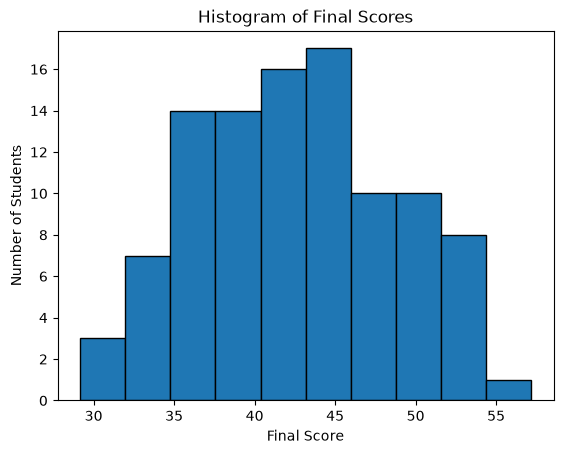

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("student_data.csv")

# Fill missing study hours and cap the outlier
df["study_hours"] = df["study_hours"].fillna(
    df["study_hours"].median()
)
df["study_hours"] = df["study_hours"].clip(upper=10)

# Histogram
plt.hist(df["final_score"], bins=10, edgecolor="black")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")
plt.title("Histogram of Final Scores")
plt.show()


### 2. Scatter plot of study_hours vs final_score

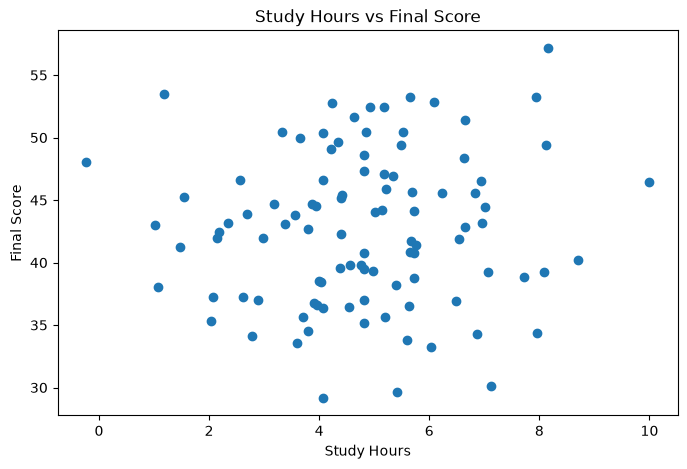

In [28]:
# Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(df['study_hours'], df['final_score'])
plt.xlabel('Study Hours')
plt.ylabel('Final Score')
plt.title('Study Hours vs Final Score')
plt.show()

# Part D — Correlation and Causality

### 1. Calculate the Pearson correlation coefficient

In [29]:
correlation = df['study_hours'].corr(df['final_score'])

print("Pearson correlation coefficient:", correlation)

Pearson correlation coefficient: 0.06498448379381212


### 2. Critical Thinking:

1. Does studying 10 hours guarantee a specific score?
No. Correlation does not guarantee a specific score. In this dataset, the correlation coefficient is 0.065, indicating a very weak positive linear relationship between study hours and final scores. Other factors also influence academic performance.
2. What is a potential confounding variable?
Previous marks could be a confounding variable. Students with higher previous marks may already understand the subject better, which could affect both their study time and their final scores.

# Part E — Vectors and Dot Product

### 1. Select one student and calculate the prediction

In [30]:
import numpy as np

# Select the first student's feature vector
x = df[['study_hours', 'attendance', 'previous_mark']].iloc[0].to_numpy()

# Define weights and bias
w = np.array([0.5, 0.2, 0.4])
b = 5

# Calculate predicted score
y = np.dot(w, x) + b

print("Feature vector:", x)
print("Predicted score:", y)

Feature vector: [ 4.8123416  70.84629258 75.36681041]
Predicted score: 51.72215347600458


### 2. Conceptual questions

1. What does the weight vector represent?
The weight vector [0.5, 0.2, 0.4] represents the importance assigned to each input feature when predicting a student's score. Study hours has a weight of 0.5, attendance has 0.2, and previous marks has 0.4. Larger weights mean a larger contribution per unit of the corresponding feature, assuming the other features stay constant.
2. Why do we need the bias?
The bias b = 5 is a constant added to the weighted sum. It allows the prediction to shift up or down independently of the input values. Without a bias, the prediction would be zero whenever all input features were zero. In a trained model, the weights and bias are usually learned from data. Here, they are predefined for the exercise.

# Part F — Scaling

### 1. Standardize study_hours and previous_mark

In [31]:
# Standardize study_hours
df['study_hours_scaled'] = (
    df['study_hours'] - df['study_hours'].mean()
) / df['study_hours'].std()

# Standardize previous_mark
df['previous_mark_scaled'] = (
    df['previous_mark'] - df['previous_mark'].mean()
) / df['previous_mark'].std()

# Display original and standardized columns
display(df[['study_hours', 'study_hours_scaled',
            'previous_mark', 'previous_mark_scaled']].head())

,study_hours,study_hours_scaled,previous_mark,previous_mark_scaled
0,4.812342,0.009627,75.366810,0.270124
1,4.812342,0.009627,78.411768,0.457342
2,4.812342,0.009627,86.245769,0.939012
3,4.812342,0.009627,85.807031,0.912037
4,4.812342,0.009627,49.334959,-1.330433


### 2. Why do we need scaling for K-Nearest Neighbors (KNN)?

##### KNN uses distances to identify the nearest data points. Without scaling, previous_mark can have a much greater influence on the distance calculation because its numerical range is larger than that of study_hours.
For example:
- study_hours typically ranges from around 0 to 10 after capping.
- previous_mark ranges roughly from 21 to 128 in the original dataset.
As a result, differences in previous marks could dominate the distance calculation, making study hours less influential.
Conclusion: Standardization puts both features on a comparable scale, allowing KNN to consider them more fairly when calculating distances.